In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/srisyra02/e-commerce-sales-performance-analysis/E-Commerce Sales Analytics.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/srisyra02/e-commerce-sales-performance-analysis/E-Commerce Sales Analytics.csv')

In [3]:
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [4]:
df.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')

In [5]:
df.shape

(5000, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


In [7]:
df.isna().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [10]:
df['product_category'].value_counts()

product_category
Electronics    1777
Clothing       1531
Home            969
Beauty          723
Name: count, dtype: int64

In [11]:
df['region'].value_counts()

region
West     1289
North    1276
East     1227
South    1208
Name: count, dtype: int64

In [12]:
df['payment_method'].value_counts()

payment_method
Card      2270
COD       1774
Wallet     956
Name: count, dtype: int64

In [13]:
df['order_date'].head(10)

0     1/1/2022
1     1/2/2022
2     1/3/2022
3     1/4/2022
4     1/5/2022
5     1/6/2022
6     1/7/2022
7     1/8/2022
8     1/9/2022
9    1/10/2022
Name: order_date, dtype: object

In [14]:
df['order_date'] = pd.to_datetime(df['order_date'])

In [15]:
df['order_date'].dtype

dtype('<M8[ns]')

In [16]:
df['order_date'].min(), df['order_date'].max()

(Timestamp('2022-01-01 00:00:00'), Timestamp('2035-09-09 00:00:00'))

In [16]:
df['order_date'].sort_values(ascending=False).head(10)

4999   2035-09-09
4998   2035-09-08
4997   2035-09-07
4996   2035-09-06
4995   2035-09-05
4994   2035-09-04
4993   2035-09-03
4992   2035-09-02
4991   2035-09-01
4990   2035-08-31
Name: order_date, dtype: datetime64[ns]

In [17]:
df['order_date'].dt.year.value_counts().sort_index()

order_date
2022    365
2023    365
2024    366
2025    365
2026    365
2027    365
2028    366
2029    365
2030    365
2031    365
2032    366
2033    365
2034    365
2035    252
Name: count, dtype: int64

### Date Validation

The `order_date` column was converted from an object/text data type to a datetime format to support time-based analysis.

The dates range from January 1, 2022 through September 9, 2035. The yearly distribution shows complete calendar-year coverage from 2022 through 2034, with 252 days recorded in 2035 through September 9.

The 2035 dates were initially investigated because the end date appeared unusual. However, the dates follow a consistent daily sequence rather than appearing to be isolated or corrupted values. Therefore, no dates were removed or modified.

**Decision:** Retain all `order_date` values.

In [18]:
df['order_id'].duplicated().sum()

np.int64(0)

### Order ID Validation

The `order_id` column was checked for duplicate identifiers. No duplicate order IDs were found, confirming that each order record has a unique identifier.

**Decision:** Retain all order records.

In [19]:
(df['quantity']<=0).sum()

np.int64(0)

### Quantity Validation

The `quantity` column was checked for zero or negative values, which would represent invalid order quantities. No invalid values were found.

**Decision:** Retain all `quantity` values.

In [20]:
(df['unit_price']<=0).sum()

np.int64(0)

In [21]:
((df['discount'] < 0) | (df['discount'] > 1)).sum()

np.int64(0)

In [22]:
(df['delivery_days'] <=0).sum()

np.int64(0)

In [23]:
((df['customer_rating'] <1) | (df['customer_rating'] >5)).sum()

np.int64(0)

In [24]:
expected_revenue = (
    df['quantity']
    * df['unit_price']
    * (1 - df['discount'])
)

difference = df['revenue'] - expected_revenue

difference.describe()

count    5000.000000
mean       -0.000029
std         0.002831
min        -0.005000
25%        -0.002400
50%         0.000000
75%         0.002400
max         0.005000
dtype: float64

### Revenue Validation

Revenue was validated against the expected calculation:

**Revenue = Quantity × Unit Price × (1 − Discount)**

The calculated revenue values closely matched the dataset's existing `revenue` values. Differences ranged from approximately -$0.005 to $0.005, which is consistent with rounding to two decimal places.

**Decision:** The existing `revenue` values were retained because they are consistent with the underlying order information.

In [25]:
Q1 = df['revenue'].quantile(0.25)
Q3 = df['revenue'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

Q1, Q3, IQR, lower_bound, upper_bound

(np.float64(354.5275),
 np.float64(1515.69),
 np.float64(1161.1625000000001),
 np.float64(-1387.2162500000002),
 np.float64(3257.43375))

In [26]:
revenue_outliers = df[df['revenue'] > upper_bound]

revenue_outliers.shape[0]

67

In [27]:
revenue_outliers[['order_id', 'quantity', 'unit_price', 'discount', 'revenue']] \
    .sort_values('revenue', ascending=False) \
    .head(10)

,order_id,quantity,unit_price,discount,revenue
809,10810,7,594.42,0.01,4119.33
4883,14884,7,583.31,0.00,4083.17
2214,12215,7,591.15,0.02,4055.29
3101,13102,7,596.12,0.04,4005.93
3686,13687,7,578.59,0.03,3928.63
157,10158,7,571.07,0.02,3917.54
3349,13350,7,574.15,0.03,3898.48
321,10322,7,585.43,0.05,3893.11
661,10662,7,581.67,0.05,3868.11
4305,14306,7,555.09,0.02,3807.92


### Revenue Outlier Investigation

The IQR method identified 67 revenue values above the upper outlier threshold of $3,257.43.

The potential outliers were investigated by examining order quantity, unit price, discount, and revenue. The highest-revenue orders generally combined higher quantities with higher unit prices, which naturally resulted in larger transaction values.

Revenue had previously been validated against the expected calculation:

**Revenue = Quantity × Unit Price × (1 − Discount)**

The potential outliers were consistent with this calculation and did not appear to be data-entry errors.

**Decision:** Retain the 67 potential revenue outliers because they represent legitimate high-value transactions rather than invalid data.

In [28]:
numeric_columns = [
    'quantity',
    'unit_price',
    'discount',
    'delivery_days',
    'customer_rating',
    'revenue'
]

df[numeric_columns].describe()

,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


## Data Cleaning & Validation Summary

The dataset was systematically reviewed for missing values, duplicate records, incorrect data types, inconsistent categorical values, invalid numerical values, and potential outliers.

### Cleaning performed

- Confirmed the dataset contains 5,000 records and 12 columns.
- Verified that no missing values were present.
- Verified that no exact duplicate rows were present.
- Confirmed that all `order_id` values are unique.
- Converted `order_date` from text to datetime format for time-based analysis.
- Reviewed the date range and confirmed that the dates follow a consistent sequence.
- Verified that product categories, regions, and payment methods contain consistent categorical values.
- Confirmed that quantity, unit price, discount, delivery days, and customer rating contain valid values within their expected ranges.
- Validated `revenue` against the expected calculation:

  **Revenue = Quantity × Unit Price × (1 − Discount)**

- Investigated 67 potential revenue outliers identified using the IQR method.
- Determined that the potential revenue outliers represent legitimate high-value transactions rather than data errors.

### Final decision

No records were removed because the validation checks did not identify data-entry errors requiring removal.

The cleaned dataset is suitable for exploratory analysis and visualization.

# Exploratory Data Analysis

The cleaned dataset was analyzed to identify key sales performance metrics, product trends, regional performance, customer behavior, and changes in revenue over time.

## Key Performance Indicators (KPIs)

The initial analysis focuses on total revenue, order volume, average order value, units sold, customer ratings, and delivery performance.

In [29]:
total_revenue = df['revenue'].sum()
total_orders = df['order_id'].nunique()
total_units = df['quantity'].sum()
average_order_value = df['revenue'].mean()
average_rating = df['customer_rating'].mean()
average_delivery_days = df['delivery_days'].mean()

total_revenue, total_orders, total_units, average_order_value, average_rating, average_delivery_days

(np.float64(5109775.74),
 5000,
 np.int64(20224),
 np.float64(1021.955148),
 np.float64(2.9739800000000005),
 np.float64(6.1188))

In [30]:
category_revenue = (
    df.groupby('product_category')['revenue']
    .agg(['sum', 'count', 'mean'])
    .sort_values('sum', ascending=False)
)

category_revenue

,sum,count,mean
product_category,,,
Electronics,1829899.22,1777,1029.768835
Clothing,1531931.72,1531,1000.608570
Home,982083.92,969,1013.502497
Beauty,765860.88,723,1059.281992


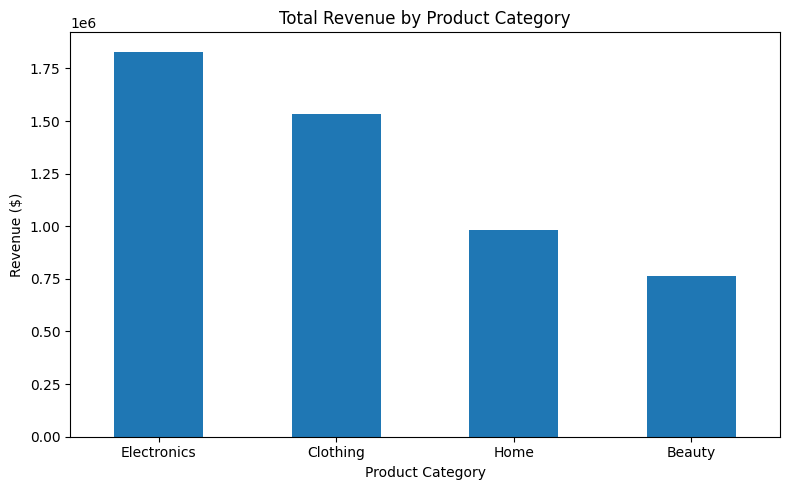

In [31]:
import matplotlib.pyplot as plt

category_revenue['sum'].plot(
    kind='bar',
    figsize=(8,5)
)

plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Revenue ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Product Category Revenue Analysis

Electronics generated the highest total revenue at approximately **$1.83 million**.

Clothing generated approximately **$1.53 million**.

Home generated approximately **$982,000**.

Beauty generated the lowest total revenue at approximately **$766,000**.

Although Beauty had the lowest total revenue, it had the highest average revenue per order at approximately **$1,059**.

This suggests that Beauty's lower overall revenue is primarily associated with lower order volume rather than substantially lower revenue per order.

**Key finding:** Electronics is the strongest revenue-generating category overall, while Beauty generates the highest revenue per order despite having the lowest sales volume.

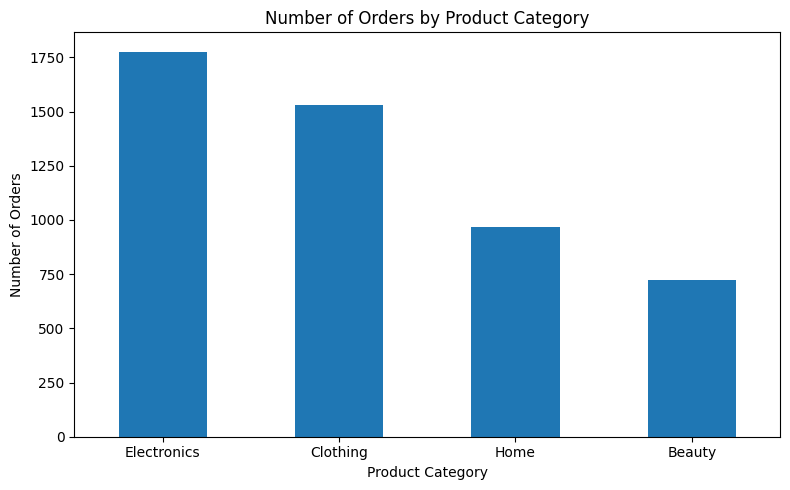

In [32]:
category_orders = (
    df['product_category']
    .value_counts()
    .sort_values(ascending=False)
)

category_orders.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Number of Orders by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
category_summary = (
    df.groupby('product_category')
    .agg(
        total_revenue=('revenue', 'sum'),
        order_count=('order_id', 'nunique'),
        average_order_value=('revenue', 'mean')
    )
    .sort_values('total_revenue', ascending=False)
)

category_summary

,total_revenue,order_count,average_order_value
product_category,,,
Electronics,1829899.22,1777,1029.768835
Clothing,1531931.72,1531,1000.608570
Home,982083.92,969,1013.502497
Beauty,765860.88,723,1059.281992


Average Order Value Analysis

Beauty had the highest average order value at approximately $1,059 per order.

Electronics averaged approximately $1,030 per order.

Home averaged approximately $1,014 per order.

Clothing had the lowest average order value at approximately $1,001 per order.

Key finding: Beauty generates the highest revenue per order despite having the lowest total sales volume, while Electronics leads total revenue primarily because of its higher number of orders.

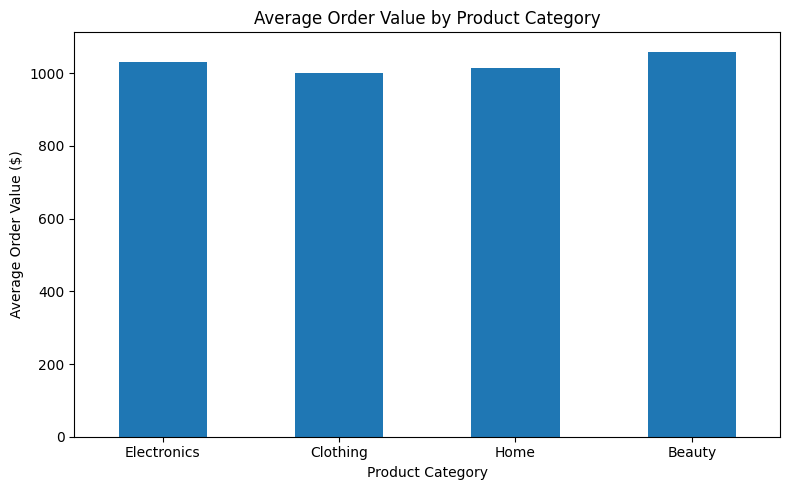

In [34]:
category_summary['average_order_value'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Order Value by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Average Order Value ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Average Order Value Analysis

**Beauty had the highest average order value** at approximately **$1,059** per order.

**Clothing had the lowest average order value** at approximately **$1,001** per order.

Electronics averaged approximately **$1,030** per order, while Home averaged approximately **$1,014** per order.

**Key finding:** Beauty generates the highest revenue per order despite having the lowest total sales volume, while Electronics leads total revenue primarily because of its higher number of orders.

### Regional Performance Analysis

Regional performance was analyzed to compare revenue, order volume, and average order value across the four sales regions.

The analysis will help identify which regions generate the most revenue, which have the highest sales volume, and whether differences in revenue are primarily driven by the number of orders or the value of each order.

In [35]:
region_summary = (
    df.groupby('region')
    .agg(
        total_revenue=('revenue', 'sum'),
        order_count=('order_id', 'nunique'),
        average_order_value=('revenue', 'mean')
    )
    .sort_values('total_revenue', ascending=False)
)

region_summary

,total_revenue,order_count,average_order_value
region,,,
West,1345582.16,1289,1043.896168
North,1281508.45,1276,1004.316967
South,1246640.90,1208,1031.987500
East,1236044.23,1227,1007.371011


In [36]:
region_revenue_share = region_summary.copy()

region_revenue_share['revenue_percentage'] = (
    region_revenue_share['total_revenue']
    / region_revenue_share['total_revenue'].sum()
) * 100

region_revenue_share = region_revenue_share.sort_values(
    by='revenue_percentage',
    ascending=False
)

region_revenue_share

,total_revenue,order_count,average_order_value,revenue_percentage
region,,,,
West,1345582.16,1289,1043.896168,26.333488
North,1281508.45,1276,1004.316967,25.079544
South,1246640.90,1208,1031.987500,24.397174
East,1236044.23,1227,1007.371011,24.189794


### Regional Revenue Share — Key Findings

The West region generated the largest share of company revenue at approximately 26.33%, followed by North at 25.08%, South at 24.40%, and East at 24.19%.

**Key finding:** Revenue is relatively evenly distributed across the four regions. The small difference between the highest and lowest revenue shares suggests that the company does not rely heavily on a single region.

**Business implication:** Management can use these results alongside order volume and average order value to identify opportunities for regional growth and improve sales performance.

In [37]:
monthly_revenue = (
    df.groupby(pd.Grouper(key='order_date', freq='MS'))['revenue']
    .sum()
    .reset_index()
)

monthly_revenue = monthly_revenue.sort_values('order_date')

monthly_revenue

,order_date,revenue
0,2022-01-01,35624.89
1,2022-02-01,29908.89
2,2022-03-01,30309.28
3,2022-04-01,30781.96
4,2022-05-01,41629.24
...,...,...
160,2035-05-01,33393.87
161,2035-06-01,25205.26
162,2035-07-01,23944.48
163,2035-08-01,29354.74


In [38]:
monthly_revenue.isna().sum()

order_date    0
revenue       0
dtype: int64

In [39]:
monthly_revenue['order_date'].is_monotonic_increasing

True

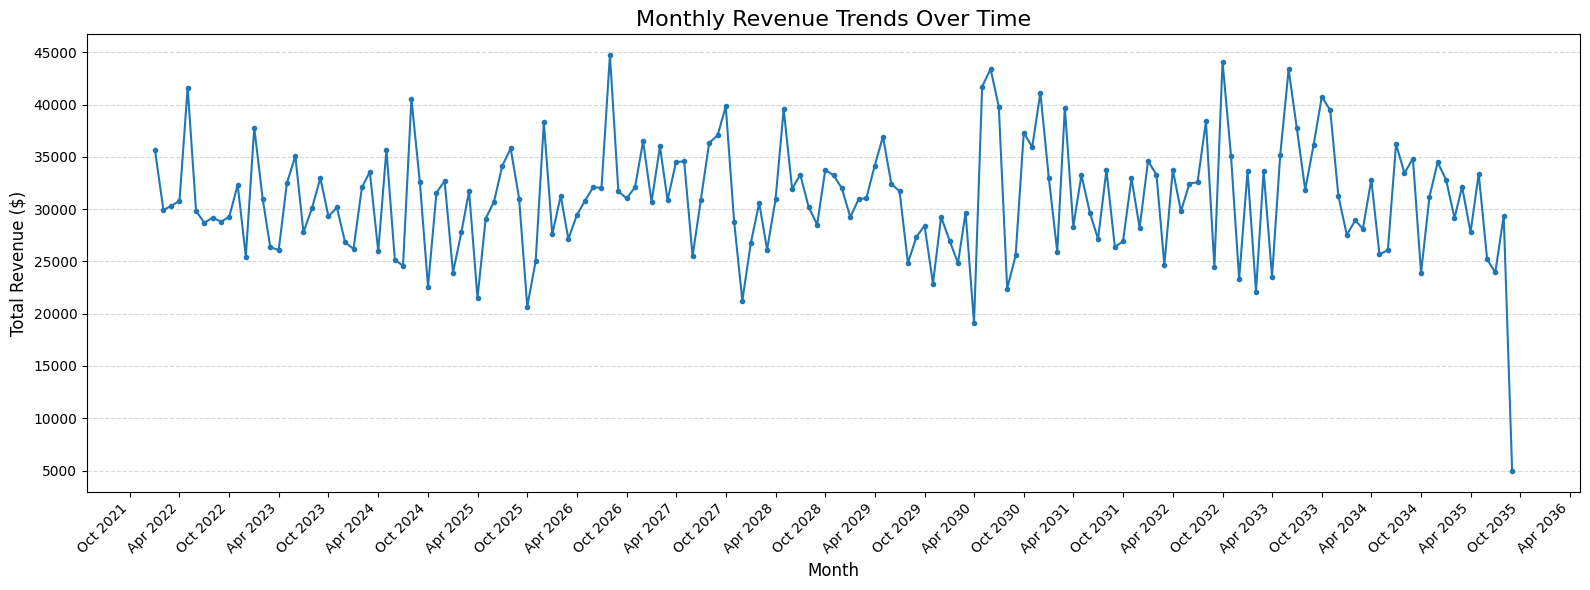

In [40]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_revenue['order_date'],
    monthly_revenue['revenue'],
    marker='o',
    markersize=3,
    linewidth=1.5
)

plt.title('Monthly Revenue Trends Over Time', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xticks(rotation=45, ha='right')

plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()

plt.show()

### Monthly Revenue Trend — Initial Findings

The monthly revenue chart shows fluctuations throughout the period rather than a consistently increasing or decreasing trend.

Revenue appears to reach higher levels around May in multiple years, suggesting a possible recurring seasonal pattern that requires further investigation.

Revenue also declines sharply in the final month of the dataset, September 2035. Because this is the final recorded month, additional validation is needed to determine whether the decline reflects a partial month of data or a genuine reduction in sales.

**Business implication:** Understanding monthly revenue fluctuations and potential recurring peaks could help the business plan promotions, inventory, and marketing activities. However, these observations should be validated before making business recommendations.

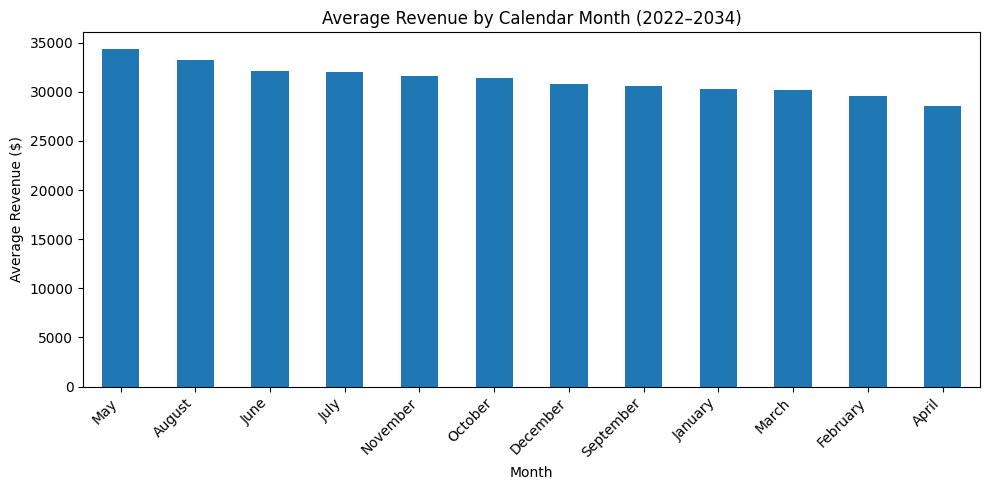

In [43]:
complete_years = monthly_revenue[
    monthly_revenue['order_date'].dt.year < 2035
].copy()

monthly_avg = (
    complete_years.groupby(complete_years['order_date'].dt.month)['revenue']
    .mean()
    .sort_values(ascending=False)
)

monthly_avg.index = monthly_avg.index.map(
    lambda month: pd.Timestamp(month=month, day=1, year=2022).strftime('%B')
)

plt.figure(figsize=(10, 5))

monthly_avg.plot(kind='bar')

plt.title('Average Revenue by Calendar Month (2022–2034)')
plt.xlabel('Month')
plt.ylabel('Average Revenue ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Key finding:** Average monthly revenue was higher in May than in April across the complete years analyzed (2022–2034). This suggests May may be a stronger sales period, although additional analysis is needed to determine whether the pattern is consistent enough to support seasonal planning.

In [44]:
revenue_changes = monthly_revenue[
    monthly_revenue['order_date'].dt.year < 2035
].copy()

revenue_changes['dollar_change'] = revenue_changes['revenue'].diff()

revenue_changes['percent_change'] = (
    revenue_changes['revenue'].pct_change() * 100
)

largest_increase = revenue_changes.loc[
    revenue_changes['dollar_change'].idxmax()
]

largest_decrease = revenue_changes.loc[
    revenue_changes['dollar_change'].idxmin()
]

print("Largest increase:")
print(largest_increase[['order_date', 'dollar_change', 'percent_change']])

print("\nLargest decrease:")
print(largest_decrease[['order_date', 'dollar_change', 'percent_change']])

Largest increase:
order_date        2030-05-01 00:00:00
dollar_change                 22626.5
percent_change             118.451568
Name: 100, dtype: object

Largest decrease:
order_date        2030-08-01 00:00:00
dollar_change               -17411.47
percent_change             -43.743049
Name: 103, dtype: object


### Month-over-Month Revenue Analysis

The largest month-over-month revenue increase occurred in May 2030, when revenue rose by $22,626.50 (118.45%) compared with April. The largest decrease occurred in August 2030, when revenue fell by $17,411.47 (43.74%) compared with July.

**Business Implication:** These substantial fluctuations may warrant further investigation to identify possible contributing factors, such as changes in order volume, product mix, or discounts. The revenue data alone does not establish the cause of either change.

In [45]:
payment_summary = df.groupby('payment_method').agg(
    unique_orders=('order_id', 'nunique'),
    total_revenue=('revenue', 'sum'),
    average_order_value=('revenue', 'mean')
)

# Sort by total revenue, highest to lowest
payment_summary = payment_summary.sort_values(
    by='total_revenue', ascending=False
)

payment_summary

,unique_orders,total_revenue,average_order_value
payment_method,,,
Card,2270,2366248.20,1042.400088
COD,1774,1788408.44,1008.122007
Wallet,956,955119.10,999.078556


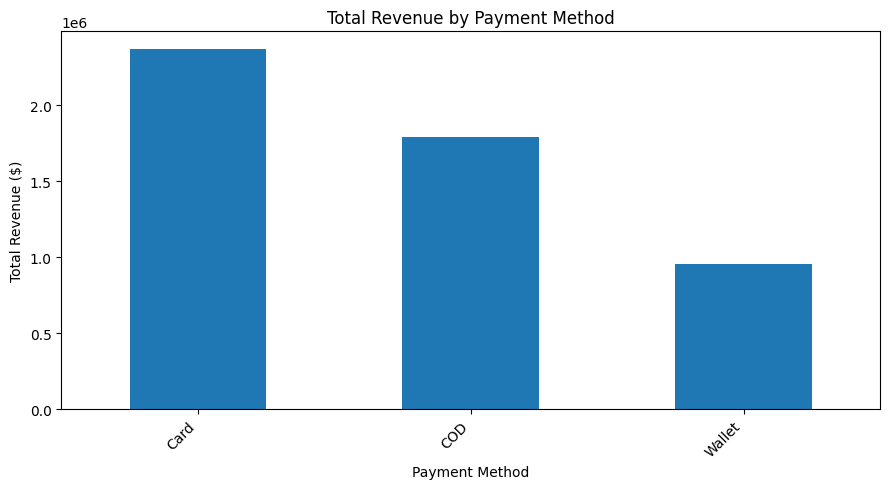

In [46]:
payment_summary['total_revenue'].plot(
    kind='bar', figsize=(9, 5)
)

plt.title('Total Revenue by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Total Revenue ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [49]:
category_summary = df.groupby('product_category').agg(
    average_rating=('customer_rating', 'mean'),
    number_of_orders=('customer_rating', 'count')
)

# Sort by average rating, highest to lowest
category_summary = category_summary.sort_values(
    by='average_rating', ascending=False
)

category_summary


,average_rating,number_of_orders
product_category,,
Beauty,3.008990,723
Clothing,3.005095,1531
Electronics,2.951097,1777
Home,2.940660,969


### Customer Rating Analysis — Findings and Implications

Beauty had the highest average customer rating at approximately 3.01 out of 5, while Home had the lowest at approximately 2.94. However, the differences between product categories were small, suggesting that customer ratings are relatively consistent across categories.

**Business Implication:** The overall ratings, averaging around 3 out of 5, suggest an opportunity to investigate customer satisfaction more closely. Additional analysis of delivery times, discounts, or other available variables may help identify factors associated with lower ratings. These results alone do not establish the cause of customer dissatisfaction.

In [52]:
region_summary = df.groupby('region').agg(
    average_rating=('customer_rating', 'mean'),
    unique_orders=('order_id', 'nunique')
)

region_summary = region_summary.sort_values(
    by='average_rating', ascending=False
)

region_summary

,average_rating,unique_orders
region,,
North,2.993182,1276
East,2.973187,1227
South,2.967798,1208
West,2.961521,1289


**Key finding:** Average customer ratings were similar across all four regions, ranging from 2.96 to 2.99 out of 5. North had the highest average rating, while West had the lowest. The small differences suggest that ratings are relatively consistent across regions.

In [54]:
delivery_summary = df.groupby('region').agg(
    average_delivery_days=('delivery_days', 'mean'),
    unique_orders=('order_id', 'nunique')
)

delivery_summary = delivery_summary.sort_values(
    by='average_delivery_days',
    ascending=False
)

delivery_summary.round(2)

,average_delivery_days,unique_orders
region,,
South,6.17,1208
North,6.12,1276
East,6.10,1227
West,6.08,1289


**Key finding:** Average delivery times were similar across all four regions, ranging from 6.08 days in the West to 6.17 days in the South. The small difference of 0.09 days suggests that delivery performance is relatively consistent across regions.

**Business implication:** The South region may warrant further investigation into delivery efficiency, but the difference is small and should not be treated as a significant operational problem without additional evidence.

In [55]:
bins = [-0.001, 0, 0.10, 0.20, 0.30, np.inf]
labels = ['0%', '1–10%', '11–20%', '21–30%', 'Above 30%']

discount_analysis = df.copy()

discount_analysis['discount_range'] = pd.cut(
    discount_analysis['discount'],
    bins=bins,
    labels=labels
)

discount_summary = discount_analysis.groupby(
    'discount_range', observed=False
).agg(
    unique_orders=('order_id', 'nunique'),
    average_discount=('discount', 'mean'),
    average_revenue_per_order=('revenue', 'mean'),
    total_revenue=('revenue', 'sum')
).reset_index()

discount_summary

,discount_range,unique_orders,average_discount,average_revenue_per_order,total_revenue
0,0%,68,0.000000,1201.277353,81686.86
1,1–10%,1333,0.054374,1157.327862,1542718.04
2,11–20%,1401,0.154461,1057.956481,1482197.03
3,21–30%,1502,0.254834,943.936385,1417792.45
4,Above 30%,696,0.327989,841.065172,585381.36


### Discount Analysis — Findings and Implications

Orders with discounts of 1–10% generated the highest total revenue at approximately $1.54 million, while orders discounted by 21–30% had the highest order volume. Average revenue per order declined as discount levels increased, from $1,201.28 for orders without discounts to $841.07 for orders with discounts above 30%.

**Business implication:** The results suggest that higher-discount orders are associated with lower revenue per order. The business could investigate whether larger discounts improve order volume enough to justify the lower revenue per order. Because revenue already accounts for discounts, these findings do not establish that discounts caused the differences.

In [56]:
quantity_summary = df.groupby('quantity').agg(
    unique_orders=('order_id', 'nunique'),
    average_revenue=('revenue', 'mean'),
    total_revenue=('revenue', 'sum')
).sort_index()

quantity_summary.round(2)

,unique_orders,average_revenue,total_revenue
quantity,,,
1,704,258.23,181791.85
2,721,507.18,365676.08
3,671,725.79,487005.22
4,718,1021.37,733343.37
5,698,1235.75,862550.77
6,713,1554.86,1108612.40
7,775,1768.77,1370796.05


**Key Findings:** Order Quantity and Revenue

Average revenue per order increased consistently with order quantity, rising from $258.23 for one-item orders to $1,768.77 for seven-item orders. Orders containing seven items generated the highest total revenue at approximately $1.37 million, followed by six-item orders at approximately $1.11 million. Order counts were relatively similar across quantity groups.

Business implication: The business could investigate opportunities to encourage larger purchases through product bundles or volume-based promotions. However, profitability and the impact of discounts should be evaluated before recommending specific incentives.

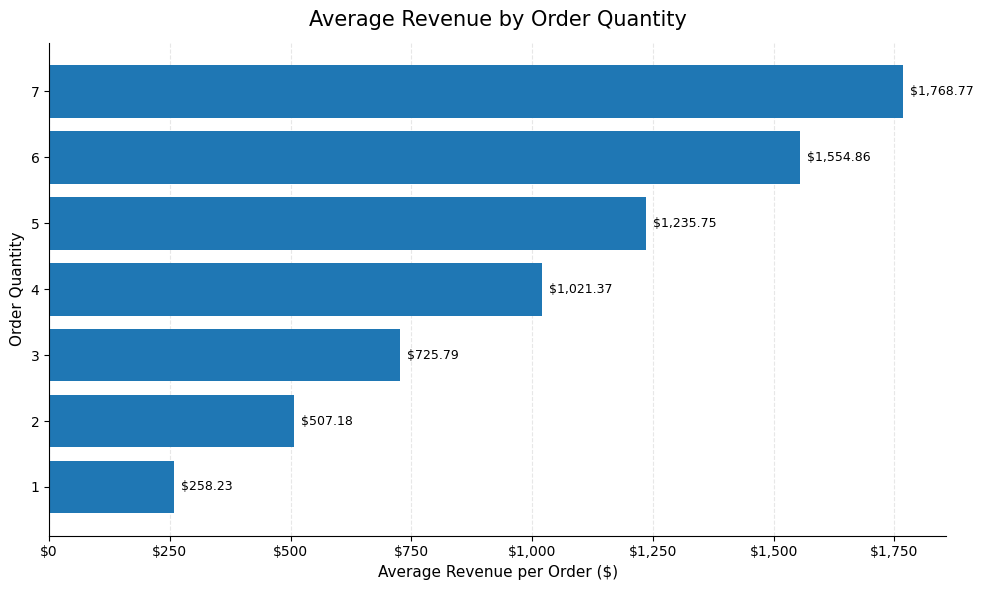

In [57]:
import matplotlib.ticker as mticker

plot_data = quantity_summary.sort_index()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_data.index.astype(str),
    plot_data['average_revenue']
)

ax.bar_label(
    bars,
    labels=[f'${value:,.2f}' for value in plot_data['average_revenue']],
    padding=5,
    fontsize=9
)

ax.set_title('Average Revenue by Order Quantity', fontsize=15, pad=12)
ax.set_xlabel('Average Revenue per Order ($)', fontsize=11)
ax.set_ylabel('Order Quantity', fontsize=11)

ax.xaxis.set_major_formatter(
    mticker.StrMethodFormatter('${x:,.0f}')
)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

In [58]:
df_cleaned = df.copy()

print("order_date data type:", df_cleaned['order_date'].dtype)

file_path = '/kaggle/working/ecommerce_cleaned.csv'
df_cleaned.to_csv(file_path, index=False)

print("Exported file:", file_path)
print("Dataset shape:", df_cleaned.shape)

order_date data type: datetime64[ns]
Exported file: /kaggle/working/ecommerce_cleaned.csv
Dataset shape: (5000, 12)


In [59]:
import os

print(os.listdir('/kaggle/working'))

['.virtual_documents', 'ecommerce_cleaned.csv']


In [60]:
import os

print(os.path.exists('/kaggle/working/ecommerce_cleaned.csv'))

True


In [61]:
from IPython.display import FileLink, display

display(FileLink('/kaggle/working/ecommerce_cleaned.csv'))

/kaggle/working/ecommerce_cleaned.csv

In [62]:
import os

print(os.listdir('/kaggle/working'))

['.virtual_documents', 'ecommerce_cleaned.csv']


In [63]:
from IPython.display import display, HTML
import base64

path = '/kaggle/working/ecommerce_cleaned.csv'

with open(path, 'rb') as f:
    encoded = base64.b64encode(f.read()).decode()

display(HTML(
    f'<a download="ecommerce_cleaned.csv" '
    f'href="data:text/csv;base64,{encoded}">'
    'Download cleaned CSV</a>'
))